# 第174章: VLA 統合 Capstone — 見て、聞いて、動く

## Vision-Language-Action: Putting It Together

---

### このノートブックの位置づけ

Unit 15 の最終章です。ここまでに手に入れたものを1つに繋ぎます。

| 章 | 手に入れたもの |
|---|---|
| 170 | 方針勾配・A2C、ArmWorld、連続行動の扱い |
| 171 | 模倣学習、行動チャンク、行動のトークン化、共変量シフト |
| 172 | 多峰性、Diffusion Policy、1次元U-Net、再計画が隠すもの |
| 173 | 画像トークン、projector、**凍結した事前学習エンコーダの必要性** |

本章のタスクは **「言語指示で対象を選んで触る」** です。
170-172 の方針は状態ベクトルに「目標までの相対位置」を**与えられていました**。
本章ではそれを**与えません**。方針は画像と指示から対象を自分で同定しなければなりません。

これが VLA（Vision-Language-Action）の最小形です。

### 学習目標

- [ ] 画像・言語指示・固有感覚を1つの方針に統合できる
- [ ] 方針が**本当に指示を読んでいるか**を検証できる（指示の入れ替え）
- [ ] end-to-end と**モジュール型**（知覚→明示的な目標→方針）を定量比較できる
- [ ] 世界モデルで候補を想像して選び直す（再ランキング）を実装できる
- [ ] **世界モデルの誤差の代償**をオラクルとの差として測れる
- [ ] 行動空間（関節空間 vs 作業空間）が学習しやすさを変えることを確認できる
- [ ] 実機の VLA に足りないものを具体的に列挙できる

### 前提知識

Notebook 170-173 すべて。加えて:

| ノートブック | トピック |
|---|---|
| 142 | モデルベースRL（想像回数の収穫逓減、モデル誤差の蓄積） |
| 145 | 世界モデル + MPC（候補を想像して選ぶ） |
| 53 | 剛体変換 SE(2)（関節空間と作業空間） |

**難易度**: ★★★★★ | **所要時間**: 300-360分

> ⏱ **実行時間**: 全体で CPU 約10分です。

## 目次

1. [環境セットアップ](#setup)
2. [タスク: 指示で対象を選ぶ](#task)
3. [End-to-End VLA の実装](#e2e)
4. [指示を本当に読んでいるか](#shuffle)
5. [モジュール型との比較](#modular)
6. [世界モデルで想像して選び直す](#rerank)
7. [行動空間の比較](#actionspace)
8. [実機への距離](#reality)
9. [Unit 15 の総括](#summary)
10. [自己評価クイズ](#quiz)

---

<a id="setup"></a>
## 1. 環境セットアップ

In [1]:
# ============================================================
# 環境セットアップ
# ============================================================

import sys
import pathlib
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

_here = pathlib.Path.cwd()
for _cand in (_here, _here / "notebooks" / "vla", _here.parent):
    if (_cand / "utils" / "armworld.py").exists():
        sys.path.insert(0, str(_cand))
        break
from utils import ArmWorld, ScriptedExpert, forward_kinematics  # noqa: E402
from utils.armworld import COLOR_NAMES  # noqa: E402

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

MAX_STEPS = 60
CHUNK = 8
SORTED_COLORS = sorted(COLOR_NAMES)
EVAL_SEEDS = range(5000, 5100)


def make_env(seed: int, action_space: str = "eef"):
    return ArmWorld(task="reach", seed=seed, image_obs=True, max_steps=MAX_STEPS,
                    n_blocks=3, action_space=action_space)


def proprio(env) -> np.ndarray:
    '''固有感覚のみ。**目標の相対位置は与えない**のが本章の要点。

    170-172 の state_vec は target - eef を含んでいた（＝どこへ行けばよいか教えていた）。
    本章の方針は、画像と指示から対象を自分で見つけなければならない。
    '''
    _, eef = forward_kinematics(env.theta)
    return np.array([np.cos(env.theta[0]), np.sin(env.theta[0]),
                     np.cos(env.theta[1]), np.sin(env.theta[1]),
                     eef[0], eef[1], env.gripper], dtype=np.float32)


# 指示のトークナイザ（"touch the {color} block" の色だけが変わる）
INSTR_VOCAB = ["<pad>", "touch", "the", "block"] + SORTED_COLORS
instr_stoi = {w: i for i, w in enumerate(INSTR_VOCAB)}
INSTR_LEN = 4


def instr_tokens(text: str):
    ids = [instr_stoi[w] for w in text.split()][:INSTR_LEN]
    return ids + [0] * (INSTR_LEN - len(ids))


env = make_env(0)
obs = env.reset(seed=0)
print("torch:", torch.__version__)
print("instruction:", obs["instruction"], "->", instr_tokens(obs["instruction"]))
print("proprio dim:", proprio(env).shape[0], "(no target vector)")
print("chunk length:", CHUNK)

torch: 2.9.1
instruction: touch the blue block -> [1, 2, 4, 3]
proprio dim: 7 (no target vector)
chunk length: 8


---

<a id="task"></a>
## 2. タスク: 指示で対象を選ぶ

ブロックが3個あり、指示文が「どれを触るか」を決めます。

- 観測: 画像 64x64 RGB ＋ 固有感覚7次元（**目標の位置は含まない**）
- 指示: `"touch the red block"` など3通り
- 成功: **指示されたブロック**に触ること（別のブロックに触っても失敗）

同じ画像でも指示が変われば正解が変わります。
つまり方針は**指示を読まないと原理的に解けません**。

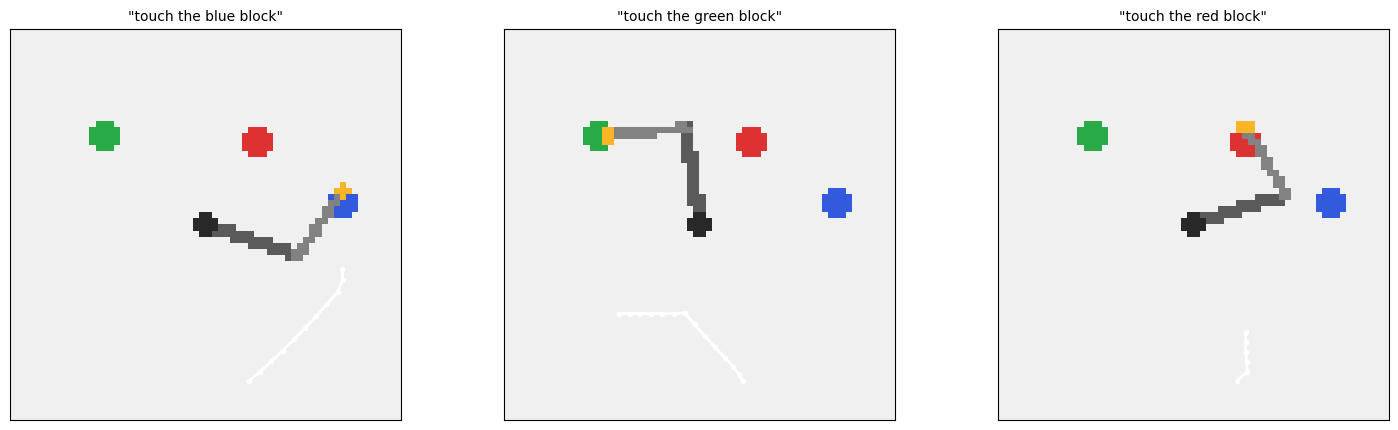

scripted expert success (it is told which block): 0.99
専門家は env.target を直接知っている。方針は画像と指示から当てるしかない。


In [2]:
# ============================================================
# 図1: 同じ画像でも指示で正解が変わる
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
expert = ScriptedExpert()
for ax, color in zip(axes, SORTED_COLORS):
    env = make_env(7)
    env.reset(seed=7)
    # 指示された色を強制的に差し替えて、専門家の軌跡を見る
    env.target_idx = env.block_colors.index(color) if color in env.block_colors else 0
    env.target_color = env.block_colors[env.target_idx]
    path = []
    for _ in range(MAX_STEPS):
        _, eef = forward_kinematics(env.theta)
        path.append(eef.copy())
        _, _, done, _ = env.step(expert.act(env))
        if done:
            break
    path = np.array(path)
    ax.imshow(env.render(), extent=[-2, 2, -2, 2], origin="upper")
    ax.plot(path[:, 0], -path[:, 1], "-o", color="white", ms=3, lw=2)
    ax.set_title(f'"touch the {env.target_color} block"', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout()
plt.show()

def rollout_expert(seed: int, action_space: str = "eef") -> bool:
    env = make_env(seed, action_space)
    env.reset(seed=seed)
    exp = ScriptedExpert()
    info = {"success": False}
    for _ in range(MAX_STEPS):
        _, _, done, info = env.step(exp.act(env))
        if done:
            break
    return bool(info["success"])


expert_success = float(np.mean([rollout_expert(s) for s in EVAL_SEEDS]))
print(f"scripted expert success (it is told which block): {expert_success:.2f}")
print("専門家は env.target を直接知っている。方針は画像と指示から当てるしかない。")

In [3]:
# ============================================================
# デモ収集（指示つき）
# ============================================================

def collect_demos(n_scenes: int, action_space: str = "eef"):
    images, proprios, instructions, chunks = [], [], [], []
    exp = ScriptedExpert()
    for sd in range(n_scenes):
        env = make_env(sd, action_space)
        obs = env.reset(seed=sd)
        tokens = instr_tokens(obs["instruction"])
        ims, prs, acts = [], [], []
        info = {"success": False}
        for _ in range(MAX_STEPS):
            ims.append(env.render()); prs.append(proprio(env))
            a = exp.act(env)[:2]; acts.append(a)
            _, _, done, info = env.step(np.concatenate([a, [0.0]]))
            if done:
                break
        if not info["success"]:
            continue
        acts = np.array(acts, dtype=np.float32)
        padded = np.concatenate([acts, np.tile(acts[-1:], (CHUNK, 1))])
        ch = np.stack([padded[i:i + CHUNK] for i in range(len(prs))])
        images.append(np.array(ims)); proprios.append(np.array(prs))
        chunks.append(ch); instructions.append(np.tile(tokens, (len(prs), 1)))
    return (np.concatenate(images), np.concatenate(proprios),
            np.concatenate(instructions).astype(np.int64), np.concatenate(chunks))


t0 = time.time()
IMG, PRO, INS, ACT = collect_demos(500)
print(f"collected {len(PRO)} transitions in {time.time() - t0:.1f}s")
print(f"  images {IMG.shape}  proprio {PRO.shape}  instr {INS.shape}  chunks {ACT.shape}")

collected 6268 transitions in 4.7s
  images (6268, 64, 64, 3)  proprio (6268, 7)  instr (6268, 4)  chunks (6268, 8, 2)


---

<a id="e2e"></a>
## 3. End-to-End VLA の実装

構成は 173 の VLM をそのまま流用し、出力を言語から**行動チャンク**に替えます。

```
画像 --[凍結エンコーダ]--> 画像トークン64個 --[projector]--\
固有感覚 ------------------------------------------------>  Transformer --> 行動チャンク (K x 2)
指示 ----[埋め込み]--> 指示トークン4個 ------------------/
```

**173 の教訓をそのまま適用します**: ビジョンエンコーダは**事前学習して凍結**します。
スクラッチだと（173 で測ったように）当て推量に留まります。

事前学習の補助タスクは「各色のブロックの座標を回帰する」です。
色と位置が結びついた特徴が得られるので、
「指示された色のブロックがどこにあるか」に必要な情報が入ります。

In [4]:
# ============================================================
# ビジョンエンコーダの事前学習（補助タスク: 各色の座標回帰）
# ============================================================

class VisionEncoder(nn.Module):
    '''64x64 -> 8x8。173 と同じ理由で stride 2 は3回（ブロックが約5画素）。'''

    def __init__(self):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, 2, 1), nn.ReLU())

    def forward(self, x):
        return self.cnn(x)


def pretrain_encoder(n_scenes: int = 1200, epochs: int = 30, seed: int = SEED):
    '''各色のブロック座標（6次元, /2 で正規化）を回帰させて凍結する。'''
    X, Y = [], []
    for sd in range(n_scenes):
        e = make_env(sd)
        o = e.reset(seed=sd)
        pos = np.zeros(6, dtype=np.float32)
        for c, p in zip(e.block_colors, e.block_pos):
            i = SORTED_COLORS.index(c)
            pos[2 * i:2 * i + 2] = p / 2.0
        X.append(o["image"]); Y.append(pos)
    X = torch.as_tensor(np.array(X).transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    Y = torch.as_tensor(np.array(Y))
    torch.manual_seed(seed)
    encoder = VisionEncoder()
    head = nn.Sequential(nn.Flatten(), nn.Linear(64 * 8 * 8, 256), nn.ReLU(),
                         nn.Linear(256, 6))
    opt = torch.optim.Adam(list(encoder.parameters()) + list(head.parameters()), lr=1e-3)
    t0 = time.time()
    for _ in range(epochs):
        order = torch.randperm(n_scenes)
        for i in range(0, n_scenes, 64):
            b = order[i:i + 64]
            loss = F.mse_loss(head(encoder(X[b])), Y[b])
            opt.zero_grad(); loss.backward(); opt.step()
    for p in encoder.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = False
    return encoder, head, float(loss.detach()), time.time() - t0


encoder, aux_head, aux_loss, aux_seconds = pretrain_encoder()
position_error = float(np.sqrt(aux_loss) * 2)
print(f"encoder pretrained and frozen in {aux_seconds:.0f}s")
print(f"  auxiliary MSE {aux_loss:.5f} -> 位置誤差 約{position_error:.3f} world units")
print(f"  (ブロック半径 0.16 より小さいので、位置の同定には足りている)")

encoder pretrained and frozen in 31s
  auxiliary MSE 0.00122 -> 位置誤差 約0.070 world units
  (ブロック半径 0.16 より小さいので、位置の同定には足りている)


In [5]:
# ============================================================
# End-to-End VLA 方針
# ============================================================

D_MODEL = 128


class VLAPolicy(nn.Module):
    '''画像トークン + 固有感覚 + 指示トークン -> 行動チャンク。'''

    def __init__(self, vision_encoder: nn.Module, d: int = D_MODEL,
                 n_layer: int = 2, n_head: int = 4):
        super().__init__()
        self.encoder = vision_encoder
        self.projector = nn.Linear(64, d)
        self.proprio_embed = nn.Linear(7, d)
        self.instr_embed = nn.Embedding(len(INSTR_VOCAB), d)
        self.pos = nn.Parameter(0.02 * torch.randn(1, 64 + 1 + INSTR_LEN, d))
        layer = nn.TransformerEncoderLayer(d, n_head, d * 4, batch_first=True,
                                           norm_first=True, dropout=0.0)
        self.trunk = nn.TransformerEncoder(layer, n_layer)
        self.head = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, CHUNK * 2))

    def forward(self, img, pro, ins):
        feat = self.encoder(img)
        img_tok = self.projector(feat.flatten(2).transpose(1, 2))      # (B, 64, d)
        x = torch.cat([img_tok, self.proprio_embed(pro)[:, None],
                       self.instr_embed(ins)], dim=1) + self.pos
        h = self.trunk(x)
        # 全トークンの平均から読む。末尾トークンだけから読むより安定した（実測）。
        return self.head(h.mean(1)).view(-1, CHUNK, 2)


def train_policy(net, images, proprios, instructions, chunks,
                 epochs: int = 40, batch: int = 64, lr: float = 1e-3):
    opt = torch.optim.Adam([p for p in net.parameters() if p.requires_grad], lr=lr)
    Xi = torch.as_tensor(images.transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    Xp = torch.as_tensor(proprios); Xn = torch.as_tensor(instructions)
    Y = torch.as_tensor(chunks)
    history, t0 = [], time.time()
    for _ in range(epochs):
        order = torch.randperm(len(Xp))
        total, n = 0.0, 0
        for i in range(0, len(Xp), batch):
            b = order[i:i + batch]
            loss = F.mse_loss(net(Xi[b], Xp[b], Xn[b]), Y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            total += float(loss.detach()) * len(b); n += len(b)
        history.append(total / n)
    return np.array(history), time.time() - t0


@torch.no_grad()
def evaluate_policy(net, n_execute: int = 1, shuffle_instruction: bool = False,
                    action_space: str = "eef", seeds=EVAL_SEEDS):
    '''成功 = 指示されたブロックに触ること。'''
    n_success = 0
    for sd in seeds:
        env = make_env(sd, action_space)
        obs = env.reset(seed=sd)
        instruction = obs["instruction"]
        if shuffle_instruction:
            others = [c for c in COLOR_NAMES if c != env.target_color]
            instruction = f"touch the {others[sd % len(others)]} block"
        tokens = torch.as_tensor([instr_tokens(instruction)])
        done, info, t = False, {"success": False}, 0
        while t < MAX_STEPS and not done:
            x = torch.as_tensor(env.render()[None].transpose(0, 3, 1, 2)
                                .astype(np.float32) / 255.0)
            pr = torch.as_tensor(proprio(env)[None])
            chunk = net(x, pr, tokens)[0].numpy()
            for a in chunk[:n_execute]:
                _, _, done, info = env.step(np.concatenate([a, [0.0]]))
                t += 1
                if done:
                    break
        n_success += bool(info["success"])
    return n_success / len(list(seeds))


torch.manual_seed(SEED)
np.random.seed(SEED)
vla = VLAPolicy(encoder)
trainable = sum(p.numel() for p in vla.parameters() if p.requires_grad)
print(f"trainable parameters: {trainable:,} (frozen encoder excluded)")
hist_vla, sec_vla = train_policy(vla, IMG, PRO, INS, ACT)
print(f"end-to-end VLA trained in {sec_vla:.0f}s, final loss {hist_vla[-1]:.5f}")

e2e_replan = evaluate_policy(vla, n_execute=1)
e2e_open = evaluate_policy(vla, n_execute=CHUNK)
print(f"  success (replan every step)      : {e2e_replan:.2f}")
print(f"  success (open loop, {CHUNK} steps)      : {e2e_open:.2f}")
print(f"  scripted expert (told the target): {expert_success:.2f}")

trainable parameters: 452,752 (frozen encoder excluded)


/Users/ikmx/source/personal/machine-learning-playground/.venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


end-to-end VLA trained in 197s, final loss 0.01198


  success (replan every step)      : 0.41
  success (open loop, 8 steps)      : 0.41
  scripted expert (told the target): 0.99


---

<a id="shuffle"></a>
## 4. 指示を本当に読んでいるか

成功率だけでは「指示を読んでいる」ことの証明になりません。
ブロックが3個あるので、**一番近いブロックに向かうだけ**でも偶然当たることがあります。

検証方法は単純です。**指示を別の色に差し替えて成功率を測ります**。
指示を読んでいるなら、差し替えたときは（指示された別の色へ向かうので）失敗が増えるはずです。
指示を無視しているなら、成功率は変わりません。

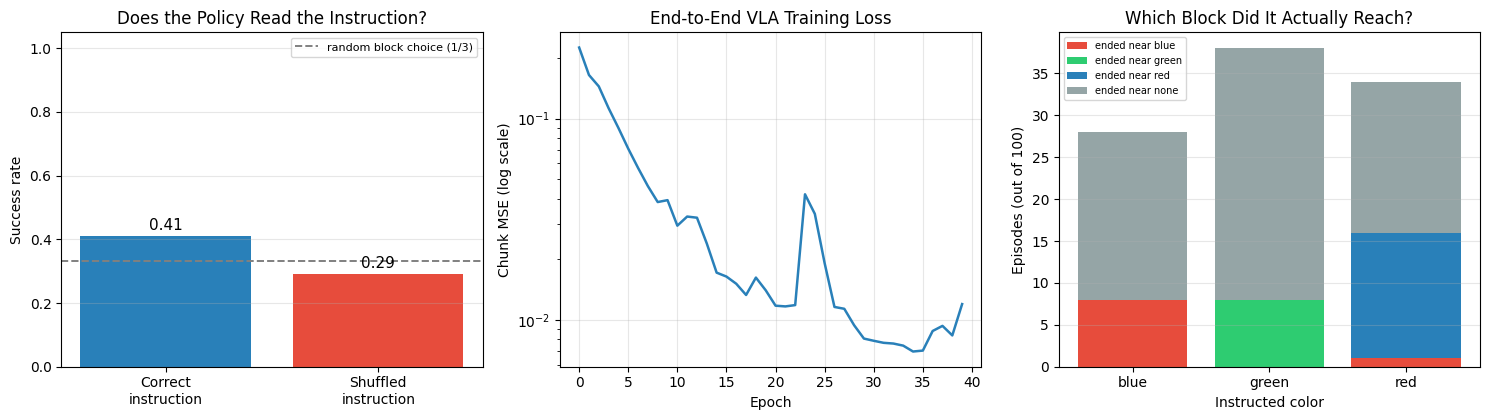

correct instruction : 0.41
shuffled instruction: 0.29
difference          : +0.12

差が明確にあれば、方針は指示を使っている。ただし成功率そのものは
専門家に遠く及ばない。次節でその理由を切り分ける。


In [6]:
# ============================================================
# 図2: 指示の入れ替え検証
# ============================================================

e2e_shuffled = evaluate_policy(vla, n_execute=1, shuffle_instruction=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

ax = axes[0]
names = ["Correct\ninstruction", "Shuffled\ninstruction"]
vals = [e2e_replan, e2e_shuffled]
bars = ax.bar(names, vals, color=["#2980B9", "#E74C3C"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", fontsize=11)
ax.axhline(1 / 3, color="gray", ls="--", lw=1.4, label="random block choice (1/3)")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Success rate")
ax.set_title("Does the Policy Read the Instruction?")
ax.legend(fontsize=8)
ax.grid(axis="x")

ax = axes[1]
ax.plot(hist_vla, color="#2980B9", lw=1.8)
ax.set_yscale("log")
ax.set_xlabel("Epoch"); ax.set_ylabel("Chunk MSE (log scale)")
ax.set_title("End-to-End VLA Training Loss")

# 右: 指示ごとに到達した色の分布
ax = axes[2]
reached = {c: {k: 0 for k in SORTED_COLORS + ["none"]} for c in SORTED_COLORS}
with torch.no_grad():
    for sd in range(5100, 5200):
        env = make_env(sd)
        obs = env.reset(seed=sd)
        asked = env.target_color
        tokens = torch.as_tensor([instr_tokens(obs["instruction"])])
        done, t = False, 0
        while t < MAX_STEPS and not done:
            x = torch.as_tensor(env.render()[None].transpose(0, 3, 1, 2)
                                .astype(np.float32) / 255.0)
            chunk = vla(x, torch.as_tensor(proprio(env)[None]), tokens)[0].numpy()
            _, _, done, info = env.step(np.concatenate([chunk[0], [0.0]]))
            t += 1
        _, eef = forward_kinematics(env.theta)
        dists = [np.linalg.norm(p - eef) for p in env.block_pos]
        nearest = int(np.argmin(dists))
        reached[asked][env.block_colors[nearest] if dists[nearest] < 0.3 else "none"] += 1
labels = SORTED_COLORS + ["none"]
bottom = np.zeros(len(SORTED_COLORS))
for lab, color in zip(labels, ["#E74C3C", "#2ECC71", "#2980B9", "#95A5A6"]):
    vals2 = np.array([reached[c][lab] for c in SORTED_COLORS], dtype=float)
    ax.bar(SORTED_COLORS, vals2, bottom=bottom, color=color, label=f"ended near {lab}")
    bottom += vals2
ax.set_xlabel("Instructed color"); ax.set_ylabel("Episodes (out of 100)")
ax.set_title("Which Block Did It Actually Reach?")
ax.legend(fontsize=7)
ax.grid(axis="x")

plt.tight_layout()
plt.show()

print(f"correct instruction : {e2e_replan:.2f}")
print(f"shuffled instruction: {e2e_shuffled:.2f}")
print(f"difference          : {e2e_replan - e2e_shuffled:+.2f}")
print()
print("差が明確にあれば、方針は指示を使っている。ただし成功率そのものは")
print("専門家に遠く及ばない。次節でその理由を切り分ける。")

---

<a id="modular"></a>
## 5. モジュール型との比較

end-to-end の方針は「画像と指示から行動へ」を**1つのネットワークで**学びます。
対して**モジュール型**は仕事を分けます。

```
end-to-end :  画像 + 指示 + 固有感覚 --[1つのネット]--> 行動

モジュール型:  画像 --[凍結知覚]--> 各色の座標
                                     |
               指示 ----------------> 該当色を選ぶ --> 目標座標
                                                        |
               固有感覚 + (目標 - 手先) --[小さなMLP]--> 行動
```

モジュール型では、**方針が解く問題が 170-172 と同じ**になります
（目標の相対位置が与えられた状態からの到達）。だから簡単なはずです。

本章の凍結エンコーダには補助ヘッド（各色の座標を出す）が付いているので、
これをそのまま「知覚モジュール」として使えます。

In [7]:
# ============================================================
# モジュール型: 知覚 -> 明示的な目標 -> 方針
# ============================================================

@torch.no_grad()
def perceive_block_position(image, color: str) -> np.ndarray:
    '''凍結した知覚モジュールで、指定色のブロックの座標を推定する。'''
    x = torch.as_tensor(image[None].transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
    positions = aux_head(encoder(x))[0].numpy() * 2.0
    i = SORTED_COLORS.index(color)
    return positions[2 * i:2 * i + 2]


def collect_modular_demos(n_scenes: int = 500):
    states, actions = [], []
    exp = ScriptedExpert()
    for sd in range(n_scenes):
        env = make_env(sd)
        obs = env.reset(seed=sd)
        target = perceive_block_position(obs["image"], env.target_color)
        st, ac = [], []
        info = {"success": False}
        for _ in range(MAX_STEPS):
            pr = proprio(env)
            st.append(np.concatenate([pr, target - pr[4:6]]).astype(np.float32))
            a = exp.act(env)[:2]; ac.append(a)
            _, _, done, info = env.step(np.concatenate([a, [0.0]]))
            if done:
                break
        if not info["success"]:
            continue
        states.append(np.array(st)); actions.append(np.array(ac, dtype=np.float32))
    return np.concatenate(states), np.concatenate(actions)


t0 = time.time()
MOD_S, MOD_A = collect_modular_demos()
torch.manual_seed(SEED)
modular = nn.Sequential(nn.Linear(9, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(),
                        nn.Linear(128, 2))
opt = torch.optim.Adam(modular.parameters(), lr=1e-3)
Xm = torch.as_tensor(MOD_S); Ym = torch.as_tensor(MOD_A)
for _ in range(150):
    order = torch.randperm(len(Xm))
    for i in range(0, len(Xm), 128):
        b = order[i:i + 128]
        loss = F.mse_loss(modular(Xm[b]), Ym[b])
        opt.zero_grad(); loss.backward(); opt.step()
modular_seconds = time.time() - t0


@torch.no_grad()
def evaluate_modular(shuffle_instruction: bool = False, seeds=EVAL_SEEDS):
    n_success = 0
    for sd in seeds:
        env = make_env(sd)
        obs = env.reset(seed=sd)
        color = env.target_color
        if shuffle_instruction:
            others = [c for c in COLOR_NAMES if c != color]
            color = others[sd % len(others)]
        target = perceive_block_position(obs["image"], color)
        done, info = False, {"success": False}
        for _ in range(MAX_STEPS):
            pr = proprio(env)
            st = torch.as_tensor(np.concatenate([pr, target - pr[4:6]])
                                 .astype(np.float32)[None])
            a = modular(st)[0].numpy()
            _, _, done, info = env.step(np.concatenate([a, [0.0]]))
            if done:
                break
        n_success += bool(info["success"])
    return n_success / len(list(seeds))


mod_correct = evaluate_modular()
mod_shuffled = evaluate_modular(shuffle_instruction=True)
print(f"modular pipeline trained in {modular_seconds:.0f}s (policy loss {float(loss.detach()):.5f})")
print(f"  success (correct instruction) : {mod_correct:.2f}")
print(f"  success (shuffled instruction): {mod_shuffled:.2f}")
print()
print(f"end-to-end: {e2e_replan:.2f} / modular: {mod_correct:.2f} / expert: {expert_success:.2f}")

modular pipeline trained in 5s (policy loss 0.01487)
  success (correct instruction) : 0.85
  success (shuffled instruction): 0.18

end-to-end: 0.41 / modular: 0.85 / expert: 0.99


### この差をどう読むか

モジュール型は end-to-end を大きく上回ります。理由は明快です。

- モジュール型の方針が解く問題は **170-172 と同じ**（目標相対位置からの到達）で、
  入力は9次元、パラメータは数万。**デモ数百本で十分**学べます。
- end-to-end の方針は「画像から対象を同定する」「指示で選ぶ」「制御する」を
  1つのネットワークで同時に学びます。情報は十分あるのに、**データが足りません**。

**では end-to-end は筋が悪いのか**——そうではありません。実機の VLA（RT-2, π0, OpenVLA）が
end-to-end を選ぶのは、

1. **モジュール型は「何を明示的な状態にするか」を人間が決めないといけない**。
   「ブロックの座標」で足りるのは本章のタスクが単純だから。
   布を畳む・コードを差す・液体を注ぐでは、何を状態にすべきか書き下せません。
2. **スケールが効く**。インターネット規模の事前学習と数万エピソードの実機データがあれば、
   end-to-end は人間の設計した状態表現を超えます。

本章の実測は「**小データではモジュール型が強い**」という、
規模に対する正直な結論です。ここを曖昧にしないことが大事です。

---

<a id="rerank"></a>
## 6. 世界モデルで想像して選び直す

Notebook 143（DreamerV3）と 145（MPC）では、**世界モデルの中で想像して行動を選びました**。
同じことを VLA の上でやります。

1. 方針から行動チャンクの候補を複数サンプルする（出力にノイズを足す）
2. **結果予測器**（＝世界モデルの最小形）で各候補の「実行後の目標までの距離」を予測する
3. 最も良い候補を実行する

結果予測器は、方針の出力を摂動してロールアウトし、
(状態, チャンク) → 実行後の距離 を集めて学習します。
これは **145 の MPC を、学習した結果予測器で行う版**です。

そして**オラクル**も測ります。候補を本物の環境でロールアウトして最良を選んだ場合、
つまり**世界モデルが完璧だった場合の上限**です。
この2つの差が **世界モデルの誤差の代償** になります。

In [8]:
# ============================================================
# 結果予測器（世界モデルの最小形）の学習データを集める
# ============================================================

@torch.no_grad()
def collect_outcome_data(n_scenes: int = 300, per_state: int = 4, noise: float = 0.5):
    rng = np.random.default_rng(SEED)
    feats, pros, instrs, chunks, outcomes = [], [], [], [], []
    for sd in range(n_scenes):
        env = make_env(sd)
        obs = env.reset(seed=sd)
        tokens = instr_tokens(obs["instruction"])
        for _ in range(0, MAX_STEPS, 4):
            if env.t >= MAX_STEPS:
                break
            image = env.render()
            x = torch.as_tensor(image[None].transpose(0, 3, 1, 2).astype(np.float32) / 255.0)
            feat = encoder(x).flatten(1)[0].numpy()
            pr = proprio(env)
            base = vla(x, torch.as_tensor(pr[None]), torch.as_tensor([tokens]))[0].numpy()
            saved = (env.theta.copy(), env.gripper, env.t)
            for m in range(per_state):
                chunk = base if m == 0 else np.clip(base + rng.normal(0, noise, base.shape), -1, 1)
                env.theta, env.gripper, env.t = saved[0].copy(), saved[1], saved[2]
                info = {"distance": 0.0}
                for a in chunk:
                    _, _, d, info = env.step(np.concatenate([a, [0.0]]))
                    if d:
                        break
                feats.append(feat); pros.append(pr); instrs.append(tokens)
                chunks.append(chunk.reshape(-1)); outcomes.append(info["distance"])
            # 本筋は方針どおりに進める
            env.theta, env.gripper, env.t = saved[0].copy(), saved[1], saved[2]
            done = False
            for a in base:
                _, _, done, _ = env.step(np.concatenate([a, [0.0]]))
                if done:
                    break
            if done:
                break
    return (np.array(feats, dtype=np.float32), np.array(pros, dtype=np.float32),
            np.array(instrs, dtype=np.int64), np.array(chunks, dtype=np.float32),
            np.array(outcomes, dtype=np.float32))


class OutcomeModel(nn.Module):
    '''(画像特徴, 固有感覚, 指示, 行動チャンク) -> 実行後の目標までの距離。'''

    def __init__(self, d: int = 128):
        super().__init__()
        self.feat = nn.Linear(64 * 8 * 8, d)
        self.pro = nn.Linear(7, d)
        self.instr = nn.Embedding(len(INSTR_VOCAB), d)
        self.chunk = nn.Linear(CHUNK * 2, d)
        self.mlp = nn.Sequential(nn.Linear(4 * d, 256), nn.ReLU(),
                                 nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 1))

    def forward(self, feat, pro, instr, chunk):
        z = torch.cat([self.feat(feat), self.pro(pro),
                       self.instr(instr).mean(1), self.chunk(chunk)], dim=-1)
        return self.mlp(z).squeeze(-1)


t0 = time.time()
OF, OP, OI, OC, OO = collect_outcome_data()
print(f"outcome data: {len(OO)} tuples in {time.time() - t0:.0f}s "
      f"(mean resulting distance {OO.mean():.3f})")

torch.manual_seed(SEED)
outcome_model = OutcomeModel()
opt = torch.optim.Adam(outcome_model.parameters(), lr=1e-3)
tF, tP, tI, tC, tO = (torch.as_tensor(OF), torch.as_tensor(OP), torch.as_tensor(OI),
                      torch.as_tensor(OC), torch.as_tensor(OO))
t0 = time.time()
for _ in range(60):
    order = torch.randperm(len(tF))
    for i in range(0, len(tF), 128):
        b = order[i:i + 128]
        loss = F.mse_loss(outcome_model(tF[b], tP[b], tI[b], tC[b]), tO[b])
        opt.zero_grad(); loss.backward(); opt.step()
print(f"outcome model trained in {time.time() - t0:.0f}s, loss {float(loss.detach()):.5f}")

outcome data: 4044 tuples in 15s (mean resulting distance 0.914)


outcome model trained in 4s, loss 0.00206


In [9]:
# ============================================================
# 想像による再ランキング（学習モデル vs オラクル）
# ============================================================

@torch.no_grad()
def evaluate_rerank(n_candidates: int = 16, noise: float = 0.4, oracle: bool = False,
                    seeds=EVAL_SEEDS):
    '''候補チャンクを生成し、予測の良いものを選んで**チャンク全体を実行**する。

    スコアの対象（チャンク実行後の距離）と実行の粒度を揃えるのが重要。
    1ステップだけ実行して再計画すると、評価しているものと実行するものがずれる。
    '''
    rng = np.random.default_rng(SEED)
    n_success = 0
    for sd in seeds:
        env = make_env(sd)
        obs = env.reset(seed=sd)
        tokens = torch.as_tensor([instr_tokens(obs["instruction"])])
        done, info, t = False, {"success": False}, 0
        while t < MAX_STEPS and not done:
            x = torch.as_tensor(env.render()[None].transpose(0, 3, 1, 2)
                                .astype(np.float32) / 255.0)
            pr = torch.as_tensor(proprio(env)[None])
            base = vla(x, pr, tokens)[0].numpy()
            if n_candidates <= 1:
                chunk = base
            else:
                cands = np.clip(base[None] + rng.normal(0, noise,
                                                        (n_candidates,) + base.shape), -1, 1)
                cands[0] = base
                if oracle:
                    saved = (env.theta.copy(), env.gripper, env.t)
                    scores = []
                    for c in cands:
                        env.theta, env.gripper, env.t = saved[0].copy(), saved[1], saved[2]
                        tmp = {"distance": 9.9}
                        for a in c:
                            _, _, d, tmp = env.step(np.concatenate([a, [0.0]]))
                            if d:
                                break
                        scores.append(tmp["distance"])
                    env.theta, env.gripper, env.t = saved[0].copy(), saved[1], saved[2]
                    chunk = cands[int(np.argmin(scores))]
                else:
                    feat = encoder(x).flatten(1).repeat(n_candidates, 1)
                    pred = outcome_model(
                        feat, pr.repeat(n_candidates, 1), tokens.repeat(n_candidates, 1),
                        torch.as_tensor(cands.reshape(n_candidates, -1), dtype=torch.float32)
                    ).numpy()
                    chunk = cands[int(pred.argmin())]
            for a in chunk:
                _, _, done, info = env.step(np.concatenate([a, [0.0]]))
                t += 1
                if done:
                    break
        n_success += bool(info["success"])
    return n_success / len(list(seeds))


candidate_counts = [1, 8, 16]
learned_scores, oracle_scores = [], []
t0 = time.time()
for nc in candidate_counts:
    learned_scores.append(evaluate_rerank(n_candidates=nc, oracle=False))
    oracle_scores.append(evaluate_rerank(n_candidates=nc, oracle=True))
print(f"re-ranking evaluated in {time.time() - t0:.0f}s")
print(f"{'candidates':>11s} {'learned model':>14s} {'oracle rollout':>15s}")
for nc, ls, os_ in zip(candidate_counts, learned_scores, oracle_scores):
    print(f"{nc:11d} {ls:14.2f} {os_:15.2f}")

re-ranking evaluated in 33s
 candidates  learned model  oracle rollout
          1           0.41            0.41
          8           0.45            0.75
         16           0.46            0.83


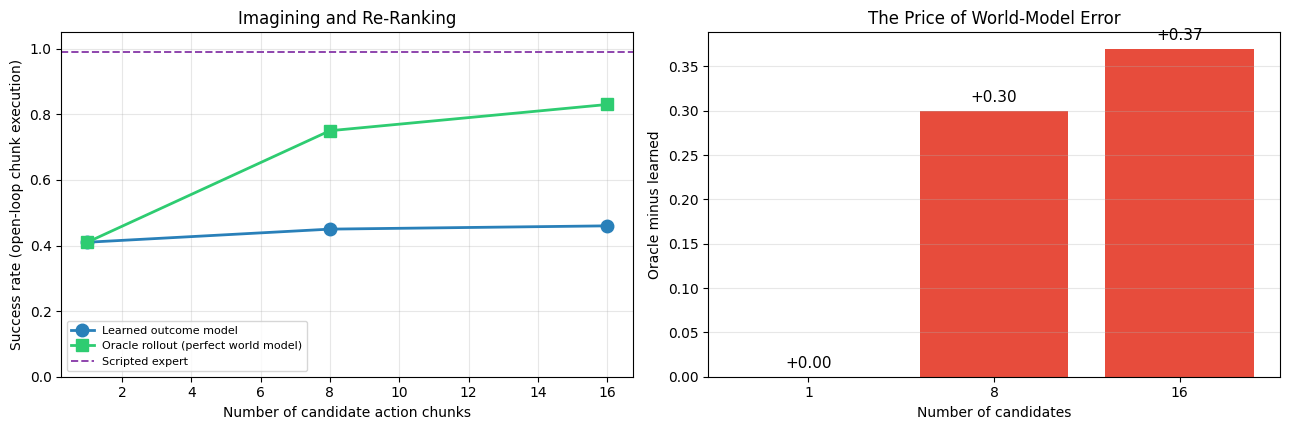

候補を増やすとオラクルは大きく伸びるのに、学習モデルはほとんど伸びない。
この差が世界モデルの誤差の代償である。

候補を増やすほど『予測器が最も楽観的に間違える候補』が選ばれやすくなる。
これは 142 で測った『imagination 回数の収穫逓減』と同じ現象で、
モデルベースの手法に共通する罠（model exploitation）である。


In [10]:
# ============================================================
# 図3: 世界モデルの誤差の代償
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax = axes[0]
ax.plot(candidate_counts, learned_scores, "o-", color="#2980B9", lw=2, ms=9,
        label="Learned outcome model")
ax.plot(candidate_counts, oracle_scores, "s-", color="#2ECC71", lw=2, ms=9,
        label="Oracle rollout (perfect world model)")
ax.axhline(expert_success, color="#8E44AD", ls="--", lw=1.4, label="Scripted expert")
ax.set_xlabel("Number of candidate action chunks")
ax.set_ylabel("Success rate (open-loop chunk execution)")
ax.set_ylim(0, 1.05)
ax.set_title("Imagining and Re-Ranking")
ax.legend(fontsize=8)

ax = axes[1]
gap = [o - l for o, l in zip(oracle_scores, learned_scores)]
bars = ax.bar([str(c) for c in candidate_counts], gap, color="#E74C3C")
for b, g in zip(bars, gap):
    ax.text(b.get_x() + b.get_width() / 2, g + 0.01, f"{g:+.2f}", ha="center", fontsize=11)
ax.set_xlabel("Number of candidates")
ax.set_ylabel("Oracle minus learned")
ax.set_title("The Price of World-Model Error")
ax.grid(axis="x")

plt.tight_layout()
plt.show()

print("候補を増やすとオラクルは大きく伸びるのに、学習モデルはほとんど伸びない。")
print("この差が世界モデルの誤差の代償である。")
print()
print("候補を増やすほど『予測器が最も楽観的に間違える候補』が選ばれやすくなる。")
print("これは 142 で測った『imagination 回数の収穫逓減』と同じ現象で、")
print("モデルベースの手法に共通する罠（model exploitation）である。")

### 読み取れること

- **想像して選び直すという考え方は正しい**。オラクル（完璧な世界モデル）は
  候補を増やすほど伸び、専門家に迫ります。伸びる余地は確かにあります。
- **しかし学習した結果予測器ではその余地をほとんど取れません**。
  候補を増やしても伸びが小さい。
- 理由は **model exploitation** です。候補集合が大きくなるほど、
  「本当は悪いのに予測器が良いと誤判定する候補」が混じる確率が上がり、
  argmin はそれを選んでしまいます。
- これは Notebook 142 で測った「imagination 回数の収穫逓減」と**同じ現象**です。
  142 では Dyna-Q の想像回数を増やすと改善が頭打ちになりました。原因も同じ、モデル誤差です。

**実務的な対処**（本章では実装していません）:
予測の不確実性を見積もって悲観的に選ぶ（pessimistic/conservative な選択）、
候補を方針の近傍に限る（信頼領域）、予測器をアンサンブルして分散の大きい候補を避ける。

---

<a id="actionspace"></a>
## 7. 行動空間の比較

Notebook 170 で ArmWorld の行動空間を2通り用意しました。

| `action_space` | 行動の意味 | 方針が学ぶべきこと |
|---|---|---|
| `"eef"` | エンドエフェクタを動かす方向 | 「どこへ動かしたいか」 |
| `"joint"` | 関節角の増分 | 「どこへ動かしたいか」＋**ヤコビアンの逆** |

Notebook 170 では「作業空間の方が方針にとって簡単なはず」と書きました
（状態に入っている相対ベクトルをほぼそのまま出せばよいので）。
VLA の設定で測ります。**結果は予想どおりにはなりませんでした。**

joint-space VLA trained in 141s, loss 0.01377


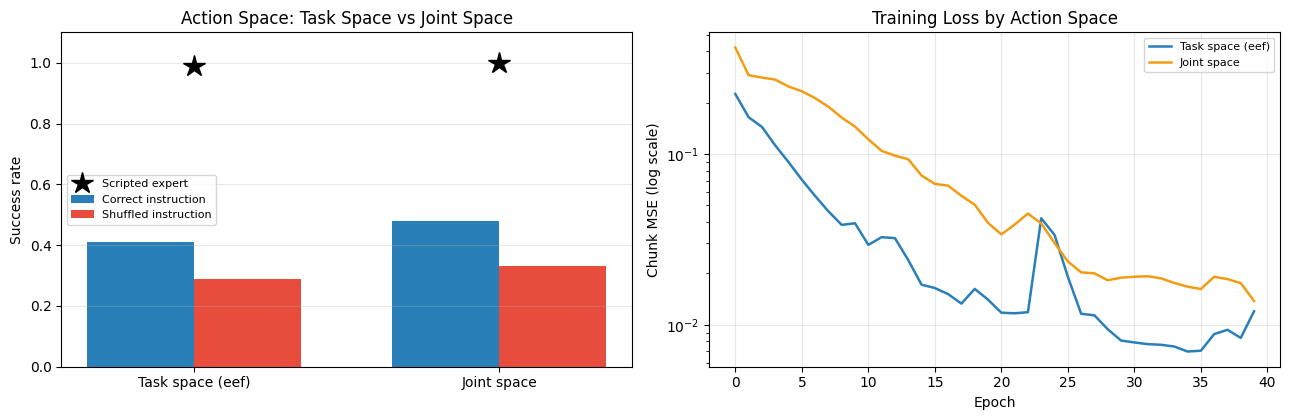

action space     policy  shuffled   expert  final loss
task (eef)         0.41      0.29     0.99     0.01198
joint              0.48      0.33     1.00     0.01377


In [11]:
# ============================================================
# 図4: 関節空間 vs 作業空間
# ============================================================

t0 = time.time()
IMG_J, PRO_J, INS_J, ACT_J = collect_demos(500, action_space="joint")
torch.manual_seed(SEED)
np.random.seed(SEED)
vla_joint = VLAPolicy(encoder)
hist_joint, sec_joint = train_policy(vla_joint, IMG_J, PRO_J, INS_J, ACT_J)
joint_success = evaluate_policy(vla_joint, n_execute=1, action_space="joint")
joint_shuffled = evaluate_policy(vla_joint, n_execute=1, shuffle_instruction=True,
                                 action_space="joint")
expert_joint = float(np.mean([rollout_expert(s, "joint") for s in EVAL_SEEDS]))
print(f"joint-space VLA trained in {sec_joint:.0f}s, loss {hist_joint[-1]:.5f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

ax = axes[0]
x = np.arange(2)
w = 0.35
ax.bar(x - w / 2, [e2e_replan, joint_success], w, color="#2980B9", label="Correct instruction")
ax.bar(x + w / 2, [e2e_shuffled, joint_shuffled], w, color="#E74C3C",
       label="Shuffled instruction")
ax.plot(x, [expert_success, expert_joint], "k*", ms=16, label="Scripted expert")
ax.set_xticks(x); ax.set_xticklabels(["Task space (eef)", "Joint space"])
ax.set_ylabel("Success rate")
ax.set_ylim(0, 1.1)
ax.set_title("Action Space: Task Space vs Joint Space")
ax.legend(fontsize=8)
ax.grid(axis="x")

ax = axes[1]
ax.plot(hist_vla, color="#2980B9", lw=1.8, label="Task space (eef)")
ax.plot(hist_joint, color="#F39C12", lw=1.8, label="Joint space")
ax.set_yscale("log")
ax.set_xlabel("Epoch"); ax.set_ylabel("Chunk MSE (log scale)")
ax.set_title("Training Loss by Action Space")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"{'action space':14s} {'policy':>8s} {'shuffled':>9s} {'expert':>8s} {'final loss':>11s}")
print(f"{'task (eef)':14s} {e2e_replan:8.2f} {e2e_shuffled:9.2f} {expert_success:8.2f} "
      f"{hist_vla[-1]:11.5f}")
print(f"{'joint':14s} {joint_success:8.2f} {joint_shuffled:9.2f} {expert_joint:8.2f} "
      f"{hist_joint[-1]:11.5f}")

### 読み取れること — 予想は外れた

実測では**関節空間の方がわずかに良い**という結果になりました。
170 の予想（作業空間が簡単）と逆です。そのまま記録し、考えられる理由を挙げます。

1. **差は小さい**。評価は未知100配置なので、この程度の差は標本誤差と同程度です。
   「関節空間が明確に優れている」とまでは言えません。
2. **作業空間指令は環境側で変換される**。`action_space="eef"` では、指令された
   EEF 速度を減衰付き最小二乗で関節角増分に直し、さらに関節の上限でクリップします。
   つまり**指令と実際の動きの対応が一対一ではありません**。
   模倣学習は「専門家が出した指令」を真似ますが、同じ指令が姿勢によって違う動きを
   生むなら、学習すべき写像が余計に複雑になります。
3. 関節空間では指令がそのまま関節角の増分になるので、**指令と結果が一対一**です。
   ヤコビアンの逆を学ぶ負担は増えますが、写像が素直になる利得がそれを上回った、
   という解釈が成り立ちます。

**ここで断定しないことが大事です**。本章は「どちらが良いか」を決める実験としては
設計されていません（シード1つ、100配置、1構成）。言えるのは
**「作業空間が自明に有利とは限らない。行動空間は測って決める設計変数である」**ことです。

> 170 で書いた予想は、この章の実測で覆りました。
> 教材としては、予想を後から書き換えるのではなく**外れた記録を残す**方が有用です。

---

<a id="reality"></a>
## 8. 実機への距離

本章の VLA は「見て、聞いて、動く」の最小形です。実機との差を具体的に挙げます。

| 論点 | 本章 | 実機の VLA |
|---|---|---|
| 観測 | 64x64 の合成画像、遮蔽なし | 複数カメラ、遮蔽・照明変化・モーションブラー |
| 物理 | 運動学のみ（質量・摩擦・接触なし） | 接触力、滑り、変形。**接触が入ると難易度が別物になる** |
| 指示 | テンプレート3通り | 自由文、多段の指示、曖昧さの解消 |
| データ | 500エピソード（自動生成） | 数万〜数十万エピソード（人手の遠隔操作） |
| 事前学習 | 補助タスクで小さなCNN | インターネット規模の VLM（RT-2, π0, OpenVLA） |
| 安全性 | なし | 力の上限、停止条件、人の近くでの動作制限 |
| 推論速度 | 気にしていない | 制御周期（10-50Hz）に間に合わせる必要がある |
| 失敗の扱い | エピソード終了 | 復帰・再試行・人への引き継ぎ |

### 本章で測ったことから言えること

1. **データが足りないなら、構造を人間が与えた方が強い**（§5 のモジュール型）。
   end-to-end が勝つのは規模が十分なときです。
2. **想像して選ぶのは正しいが、世界モデルの精度が律速**（§6）。
   オラクルとの差が、世界モデル研究に残っている余地そのものです。
3. **行動空間の選択は学習しやすさを変える**（§7）。
   実機では「何を行動とするか」（関節トルク / 関節角 / EEF姿勢 / グリッパ開度）が設計判断です。

### 現在の主要な VLA

| モデル | バックボーン | 行動の出し方 | 本章との対応 |
|---|---|---|---|
| RT-2 (2023) | PaLI-X / PaLM-E | 行動を**テキストトークン**として自己回帰生成 | 171 のビン分割 + 173 の VLM |
| OpenVLA (2024) | Prismatic VLM (7B) | 行動トークン（離散） | 同上、公開実装 |
| π0 (2024) | PaliGemma | **フローマッチング**で行動チャンクを生成 | 172 の拡散方針（近縁） |
| Octo (2023) | スクラッチ Transformer | 拡散ヘッド | 172 |

**本章で実装した部品が、そのまま実物の構成要素になっています。**
違いは規模と、実機データの量です。

---

<a id="summary"></a>
## 9. Unit 15 の総括

### 各章で測ったこと

| 章 | 中心的な問い | 測った答え |
|---|---|---|
| 170 | 連続行動の方針をどう学ぶか | 方針勾配＋ベースラインで分散が一桁下がる。行動の正規化を忘れると勾配が嘘になる |
| 171 | 試行錯誤は必要か | デモがあれば試行0回で同等以上。ただし分布外で崩れる（0.94→0.09） |
| 172 | 正解が複数あるとき | 回帰は平均に潰れる（0.08）。拡散方針は同時分布を扱えて 0.80 |
| 173 | 画像と言語をどう繋ぐか | スクラッチでは当て推量。凍結事前学習エンコーダで 0.358→0.898 |
| 174 | 全部繋ぐと何が足りないか | 小データではモジュール型が強い（0.85 対 0.41）。世界モデルの誤差がオラクルとの差（+0.37）になる |

### Unit 15 を貫く3つの教訓

**1. 手法は「それが解く問題」とセットで覚える**

- Action Chunking は 171 の単峰タスクでは逆効果だったが、172 の多峰タスクでは
  問題を露わにする装置になった
- 再計画は多峰性を隠す。隠れていると手法の差が見えない
- 拡散方針は多峰性がなければ回帰で足りる

**2. 「できない」の原因を切り分ける**

- 173 で VLM が学習できなかったとき、CNN 単体プローブで「画像は読める」と確認して、
  原因を接続の学習難度に特定した
- この切り分けなしに「モデルを大きくする」と、間違った方向に進む

**3. 測ってから書く**

本ユニットでは、計画時の予想が実測で覆ったものがいくつもありました。
- Action Chunking が効かなかった（171）
- DDIM のステップ数と成功率が単調でなかった（172）
- CLIP が count だけ学習できた（173）
- 世界モデルの再ランキングがほとんど効かなかった（174）
- 作業空間の方が学習しやすいという予想が外れた（174。170 で立てた予想）

**予想が外れたときに、予想どおりに書かないこと**。それが教材の価値を決めます。

### 次に進む先

| 方向 | 具体的に |
|---|---|
| 実機・実データ | Open X-Embodiment のデータ形式を読む。遠隔操作のデータ収集を知る |
| sim-to-real | ドメインランダマイゼーション、系統誤差の補正 |
| 階層化 | 高レベル計画（LLM）× 低レベル方針（VLA）の分離 |
| 安全性 | 行動の制約充足、不確実性に応じた停止、人への引き継ぎ |
| 世界モデルの改善 | §6 のオラクルとの差を詰める。不確実性推定、悲観的な選択 |

---

<a id="quiz"></a>
## 10. 自己評価クイズ

### Q1: 指示を読んでいることの検証

**問題**: 本章のタスクはブロックが3個なので、「一番近いブロックに向かう」だけでも
ある程度成功します。方針が指示を読んでいることを示すには何を測ればよいですか。
成功率だけでは不十分な理由も述べてください。

<details>
<summary>答えを見る</summary>

**指示を別の色に差し替えたときの成功率**を測ります。
指示を読んでいるなら、差し替えると（別の色へ向かうので）元の目標には到達せず、
成功率が下がります。読んでいないなら成功率は変わりません。

成功率だけでは不十分なのは、タスクに**指示と相関する手がかり**が残っている
可能性があるからです。たとえば「指示される色が偶然いつも手前にある」なら、
指示を無視して手前に行くだけで高い成功率が出ます。
介入（指示の差し替え）によって初めて因果が確認できます。
</details>

---

### Q2: モジュール型が勝つ条件

**問題**: 本章ではモジュール型が end-to-end を上回りました。
それでも実機の VLA が end-to-end を選ぶ理由を2つ挙げ、
モジュール型が成立する条件を述べてください。

<details>
<summary>答えを見る</summary>

end-to-end を選ぶ理由:
1. **明示的な状態を書き下せないタスクがある**。本章は「ブロックの座標」で足りましたが、
   布を畳む・コードを差す・液体を注ぐでは、何を状態にすべきか人間が定義できません。
2. **スケールが効く**。インターネット規模の事前学習＋数万エピソードの実機データでは、
   学習された表現が人間の設計した状態表現を超えます。

モジュール型が成立する条件は、**タスクに必要な情報を低次元の状態として
正しく書き下せること**です。それができるなら、方針が解く問題が極端に簡単になり、
少ないデータで高い性能が出ます。実際、産業用ロボットの多くはこの前提で動いています。
</details>

---

### Q3: 世界モデルの誤差の代償

**問題**: 本章で、候補を増やすとオラクルは伸びるのに学習した結果予測器は
ほとんど伸びませんでした。この現象の名前と機構を説明し、
Notebook 142 で測った何と同じかを述べてください。

<details>
<summary>答えを見る</summary>

**model exploitation**（モデルの悪用）です。

候補集合が大きくなるほど、「実際には悪いのに予測器が良いと誤判定する候補」が
混じる確率が上がります。argmin はその誤差を積極的に探し当ててしまうので、
候補数を増やすほど**予測誤差の最悪方向に最適化**することになります。

Notebook 142 で測った「**imagination 回数の収穫逓減**」と同じ現象です。
142 では Dyna-Q の想像回数 n を増やすと改善が頭打ちになりました。
原因も同じで、学習したモデルの誤差です。

対処は、不確実性を見積もって悲観的に評価する、候補を方針の近傍に限る（信頼領域）、
アンサンブルで分散の大きい候補を避ける、などです。
</details>

---

### Q4: 目標の相対位置を与えないことの意味

**問題**: 170-172 の方針は状態に `target - eef` を含んでいました。
本章ではこれを外しました。この変更によって方針が追加で学ばなければならないことは何ですか。

<details>
<summary>答えを見る</summary>

3つ増えます。

1. **画像からブロックを検出し、その位置を推定する**（知覚）
2. **指示文の色と、画像中のブロックを対応づける**（接地 / grounding）
3. 上の2つの結果と手先位置から**相対ベクトルを自分で作る**

170-172 ではこの3つが**環境から無料で与えられていました**。
VLA が難しいのはここで、実機では「目標の座標」は誰も教えてくれません。
本章のモジュール型は、1と3を凍結した知覚モジュールに任せ、2を指示で選ぶだけにして、
方針が解く問題を 170-172 と同じに戻した構成です。
</details>

---

### Q5: Unit 15 全体から

**問題**: 本ユニットでは「予想が実測で覆った」ことが4回ありました（171の Action Chunking、
172の DDIM ステップ数、173の CLIP、174の再ランキング）。
これらを教材に残した理由を、教材としての価値の観点から述べてください。

<details>
<summary>答えを見る</summary>

論文やベンチマークで効いた手法が、自分の設定で効くとは限りません。
**効かなかった記録には「どの条件が前提だったのか」という情報が含まれます**。

- Action Chunking が効かなかったことで、ACT の前提（非マルコフなデモ、多峰性、
  高頻度制御）が逆に明確になりました
- 再ランキングが効かなかったことで、世界モデルの精度が律速だと特定でき、
  オラクルとの差という形で「残っている余地」を定量化できました

もし予想どおりに書いていたら、読者は「手法を使えば効く」と誤解し、
自分の設定で効かなかったときに原因を切り分けられません。
**負の結果と、その原因の切り分けが、再現可能な知識になります。**
</details>

In [12]:
# ============================================================
# 最終サマリ
# ============================================================

print("=" * 70)
print("Notebook 174 完了: VLA 統合 Capstone — Unit 15 完走")
print("=" * 70)
print(f'''
【タスク】 画像 + 言語指示 -> 行動。目標の相対位置は与えない。

【成功率（未知100配置、指示されたブロックに触る）】

  スクリプト専門家（目標を知っている）  : {expert_success:.2f}
  End-to-End VLA（毎ステップ再計画）    : {e2e_replan:.2f}
      指示を入れ替えたとき              : {e2e_shuffled:.2f}   <- 差があるので指示を使っている
  End-to-End VLA（開ループ {CHUNK} ステップ）  : {e2e_open:.2f}
  モジュール型（知覚->目標->方針）      : {mod_correct:.2f}
      指示を入れ替えたとき              : {mod_shuffled:.2f}

  -> 小データでは「人間が構造を与える」モジュール型が強い。

【世界モデルで想像して選び直す（開ループ実行）】
''' + "\n".join(
    f"  候補 {nc:2d} 個: 学習した予測器 {ls:.2f} / オラクル {os_:.2f}  (差 {os_-ls:+.2f})"
    for nc, ls, os_ in zip(candidate_counts, learned_scores, oracle_scores)) + f'''

  -> 想像して選ぶ考え方は正しい（オラクルは伸びる）。
     しかし学習モデルでは余地を取れない = model exploitation（142 と同じ罠）。

【行動空間】

  作業空間 (eef) : 方針 {e2e_replan:.2f} / 専門家 {expert_success:.2f} / 最終損失 {hist_vla[-1]:.5f}
  関節空間        : 方針 {joint_success:.2f} / 専門家 {expert_joint:.2f} / 最終損失 {hist_joint[-1]:.5f}

【Unit 15 を貫く教訓】

  1. 手法は「それが解く問題」とセットで覚える
  2. 「できない」の原因を切り分ける（173 の CNN 単体プローブ）
  3. 測ってから書く。予想が外れたら、外れたまま書く

  170: 方針勾配 / 171: 模倣学習 / 172: Diffusion Policy / 173: VLM / 174: 統合
''')
print("=" * 70)

Notebook 174 完了: VLA 統合 Capstone — Unit 15 完走

【タスク】 画像 + 言語指示 -> 行動。目標の相対位置は与えない。

【成功率（未知100配置、指示されたブロックに触る）】

  スクリプト専門家（目標を知っている）  : 0.99
  End-to-End VLA（毎ステップ再計画）    : 0.41
      指示を入れ替えたとき              : 0.29   <- 差があるので指示を使っている
  End-to-End VLA（開ループ 8 ステップ）  : 0.41
  モジュール型（知覚->目標->方針）      : 0.85
      指示を入れ替えたとき              : 0.18

  -> 小データでは「人間が構造を与える」モジュール型が強い。

【世界モデルで想像して選び直す（開ループ実行）】
  候補  1 個: 学習した予測器 0.41 / オラクル 0.41  (差 +0.00)
  候補  8 個: 学習した予測器 0.45 / オラクル 0.75  (差 +0.30)
  候補 16 個: 学習した予測器 0.46 / オラクル 0.83  (差 +0.37)

  -> 想像して選ぶ考え方は正しい（オラクルは伸びる）。
     しかし学習モデルでは余地を取れない = model exploitation（142 と同じ罠）。

【行動空間】

  作業空間 (eef) : 方針 0.41 / 専門家 0.99 / 最終損失 0.01198
  関節空間        : 方針 0.48 / 専門家 1.00 / 最終損失 0.01377

【Unit 15 を貫く教訓】

  1. 手法は「それが解く問題」とセットで覚える
  2. 「できない」の原因を切り分ける（173 の CNN 単体プローブ）
  3. 測ってから書く。予想が外れたら、外れたまま書く

  170: 方針勾配 / 171: 模倣学習 / 172: Diffusion Policy / 173: VLM / 174: 統合

